# Funciones · Aplicaciones

Funciones aplicadas a finanzas y simulaciones.

## 1. Hipoteca

La cuota mensual de una hipoteca de $h$ euros a $n$ años y un interés anual del $i$ % es $m=\frac{h\,r}{1-(1+r)^{-12n}}$, con $r=\frac{i}{100\cdot12}$. Escribir funciones que calculen la cuota (redondeada a dos decimales), el total pagado, los intereses pagados y el porcentaje que suponen sobre el capital, y procedimientos que muestren la cuota y el total a 10, 15, 20 y 25 años.

Comprobación: 150 000 € a 15 años al 4.75 % → cuota 1166.75 €, total 210 015 €, intereses 60 015 € (40.01 %).

In [1]:
def cuota(h, n, i):
    r = i / (100 * 12)
    return round(h * r / (1 - (1 + r) ** (-12 * n)), 2)

def total_pagado(h, n, i):
    return cuota(h, n, i) * 12 * n

def intereses(h, n, i):
    return total_pagado(h, n, i) - h

def porcentaje_intereses(h, n, i):
    return intereses(h, n, i) / h * 100

def muestra_plazos(h, i):
    for n in (10, 15, 20, 25):
        print(f"{n} años: cuota {cuota(h, n, i):9.2f} €  total {total_pagado(h, n, i):10.2f} €")

print(cuota(150000, 15, 4.75), total_pagado(150000, 15, 4.75))
print(f"{intereses(150000, 15, 4.75):.2f} {porcentaje_intereses(150000, 15, 4.75):.2f} %")
muestra_plazos(150000, 4.75)

1166.75 210015.0
60015.00 40.01 %
10 años: cuota   1572.72 €  total  188726.40 €
15 años: cuota   1166.75 €  total  210015.00 €
20 años: cuota    969.34 €  total  232641.60 €
25 años: cuota    855.18 €  total  256554.00 €


## 2. Intereses según el plazo

Al alargar el plazo baja la cuota, pero suben los intereses. Representar en una gráfica los intereses pagados frente al plazo en años.

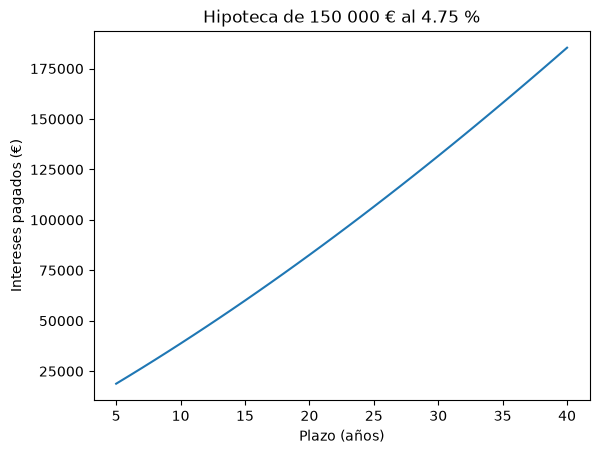

In [2]:
import matplotlib.pyplot as plt

plazos = range(5, 41)
plt.plot(plazos, [intereses(150000, n, 4.75) for n in plazos])
plt.xlabel("Plazo (años)")
plt.ylabel("Intereses pagados (€)")
plt.title("Hipoteca de 150 000 € al 4.75 %")
plt.show()

## 3. Impuestos por tramos

Con los tramos `(12000, 19 %)`, `(20000, 24 %)`, `(30000, 30 %)`, `(60000, 37 %)` y `(∞, 45 %)`, cada parte del sueldo tributa al tipo de su tramo. Escribir una función que devuelva el impuesto a pagar y el porcentaje que supone sobre el sueldo.

In [3]:
TRAMOS = [(12000, 0.19), (20000, 0.24), (30000, 0.30), (60000, 0.37), (float("inf"), 0.45)]

def impuesto(sueldo):
    total, anterior = 0, 0
    for limite, tipo in TRAMOS:
        if sueldo <= anterior:
            break
        total += (min(sueldo, limite) - anterior) * tipo
        anterior = limite
    return total, total / sueldo * 100

for sueldo in (10000, 25000, 80000):
    euros, porcentaje = impuesto(sueldo)
    print(f"{sueldo}: {euros:.2f} € ({porcentaje:.2f} %)")

10000: 1900.00 € (19.00 %)
25000: 5700.00 € (22.80 %)
80000: 27300.00 € (34.12 %)


## 4. Interés compuesto variable

Escribir `interes_compuesto(principal, intereses)`, donde `intereses` es una lista con el interés de cada año (su longitud es el número de años).

In [4]:
from math import prod

def interes_compuesto(principal, intereses):
    return principal * prod(1 + i for i in intereses)

print(f"{interes_compuesto(1000, [0.05, 0.03, -0.02, 0.04, 0.06]):.2f}")

1168.40


## 5. Simular apuestas

Se lanza una moneda: con probabilidad `prob_ganar` se gana `retorno_ganar` veces lo apostado; si no, se pierde lo apostado. Añadir el parámetro `no_apostar` (fracción del dinero que se guarda en cada apuesta), representar la evolución de 1000 personas y comparar estrategias (relacionado con el criterio de Kelly).

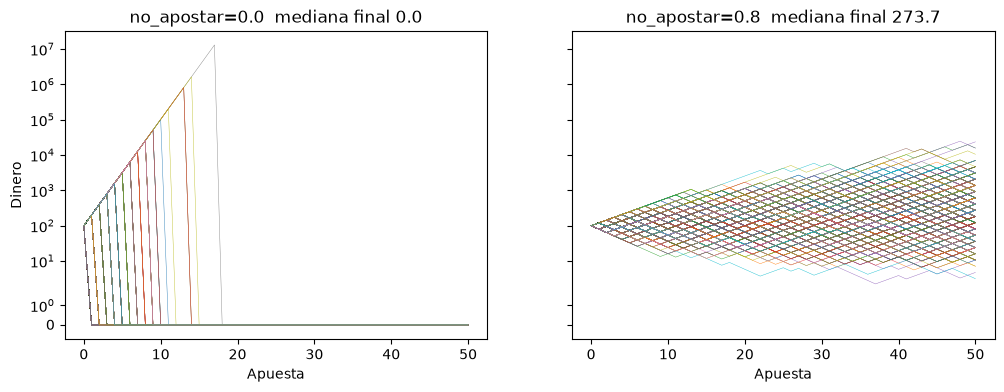

In [5]:
import random
import matplotlib.pyplot as plt

def apuesta(dinero, num_apuestas, prob_ganar=0.6, retorno_ganar=1.0, no_apostar=0.0):
    evolucion = [dinero]
    for _ in range(num_apuestas):
        apostado = dinero * (1 - no_apostar)
        dinero += apostado * retorno_ganar if random.random() < prob_ganar else -apostado
        evolucion.append(dinero)
    return evolucion

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for eje, no_apostar in zip(ejes, (0.0, 0.8)):
    finales = []
    for _ in range(1000):
        e = apuesta(100, 50, no_apostar=no_apostar)
        eje.plot(e, linewidth=0.3)
        finales.append(e[-1])
    eje.set_yscale("symlog")
    eje.set_title(f"no_apostar={no_apostar}  mediana final {sorted(finales)[500]:.1f}")
    eje.set_xlabel("Apuesta")
ejes[0].set_ylabel("Dinero")
plt.show()

## 6. Martingala

En la ruleta se apuesta siempre al negro: si se gana se vuelve a la apuesta inicial y si se pierde se dobla. Simular la estrategia y buscar parámetros que reduzcan el riesgo de bancarrota.

In [6]:
import random

def martingala(dinero, apuesta_inicial, rondas, prob_ganar=18 / 37):
    apuesta = apuesta_inicial
    for _ in range(rondas):
        if apuesta > dinero:
            return 0
        if random.random() < prob_ganar:
            dinero += apuesta
            apuesta = apuesta_inicial
        else:
            dinero -= apuesta
            apuesta *= 2
    return dinero

def prob_bancarrota(dinero, apuesta_inicial, rondas, simulaciones=5000):
    return sum(martingala(dinero, apuesta_inicial, rondas) == 0 for _ in range(simulaciones)) / simulaciones

for apuesta_inicial in (50, 10, 1):
    print(f"apuesta inicial {apuesta_inicial:>2}: bancarrota {prob_bancarrota(1000, apuesta_inicial, 200):.1%}")

apuesta inicial 50: bancarrota 95.2%
apuesta inicial 10: bancarrota 67.9%
apuesta inicial  1: bancarrota 13.4%
